# Логистическая регрессия: реализация с нуля

**Цель:** реализовать бинарную логистическую регрессию без `sklearn`: логарифмическую функцию потерь и ее градиент, градиентный спуск, предсказание классов. Затем обучить модель на синтетических данных, построить график потерь и оценить предсказания.

Используются только **NumPy** для вычислений и **Matplotlib** для графиков.

**Формат матриц:** $X \in \mathbb{R}^{n\times m}$, где $n$ — число признаков (включая константный признак для свободного члена), $m$ — число объектов; $w\in\mathbb{R}^{n\times1}$; $y\in\{0,1\}^{1\times m}$. В каждом **столбце** `X` находится один объект. Это соответствует шаблону задания с обходом `A.shape[1]`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## 1. Функция потерь и ее градиент

Вероятность положительного класса вычисляется через сигмоиду:

$$z=w^TX, \qquad \sigma(z)=\frac{1}{1+e^{-z}}.$$

Для бинарных меток используется средняя логарифмическая потеря:

$$L(w)=-\frac{1}{m}\sum_{i=1}^m\left[y_i\ln a_i+(1-y_i)\ln(1-a_i)\right],\qquad a_i=\sigma(w^Tx_i).$$

Ее градиент по всем весам в векторной форме:

$$\nabla_w L(w)=\frac{1}{m}X(A-y)^T,\qquad A=\sigma(w^TX).$$

Для вычисления логарифмов вероятности ограничиваются интервалом $[10^{-12},1-10^{-12}]$: это защищает от `log(0)`. Для градиента используются исходные значения сигмоиды.

In [2]:
def sigmoid(z):
    """Сигмоида; ограничение аргумента предотвращает переполнение exp."""
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def log_loss(w, X, y):
    """
    w: (n, 1), X: (n, m), y: (1, m).
    Возвращает (значение log loss, градиент формы (n, 1)).
    """
    m = X.shape[1]
    A = sigmoid(w.T @ X)
    A_safe = np.clip(A, 1e-12, 1 - 1e-12)

    loss = -np.mean(y * np.log(A_safe) + (1 - y) * np.log(1 - A_safe))
    grad = (X @ (A - y).T) / m
    return float(loss), grad

## 2. Градиентный спуск и предсказание

На каждом шаге параметры обновляются по формуле

$$w_{t+1}=w_t-\eta\nabla_w L(w_t),$$

где $\eta$ (`eta`) — скорость обучения. После обновления сохраняем значение функции потерь, чтобы построить график ее изменения. В `predict` класс 1 присваивается только при вероятности **строго больше** порога `b`.

In [3]:
def optimize(w, X, y, n_iterations, eta):
    """Обучает веса градиентным спуском и записывает потери после каждого шага."""
    w = np.array(w, dtype=float, copy=True)
    losses = []

    for _ in range(n_iterations):
        _, grad = log_loss(w, X, y)
        w -= eta * grad
        loss, _ = log_loss(w, X, y)
        losses.append(loss)

    return w, losses


def predict(w, X, b=0.5):
    """Возвращает бинарные классы формы (1, m)."""
    A = sigmoid(w.T @ X)
    y_predicted = (A > b).astype(int)
    return y_predicted

## 3. Проверка реализации

При нулевых весах вероятности равны 0.5 и log loss равен $\ln 2$. Градиент дополнительно проверяется методом конечных разностей: результат аналитической формулы должен совпадать с численным приближением.

In [4]:
X_check = np.array([[1., 1., 1., 1.],
                    [-1., 0., 1., 2.]])
y_check = np.array([[0, 0, 1, 1]])
w_check = np.zeros((2, 1))

loss_check, grad_check = log_loss(w_check, X_check, y_check)
assert np.isclose(loss_check, np.log(2))
assert grad_check.shape == w_check.shape

h = 1e-6
numerical_grad = np.zeros_like(w_check)
for j in range(w_check.shape[0]):
    w_plus = w_check.copy()
    w_minus = w_check.copy()
    w_plus[j, 0] += h
    w_minus[j, 0] -= h
    numerical_grad[j, 0] = (log_loss(w_plus, X_check, y_check)[0]
                            - log_loss(w_minus, X_check, y_check)[0]) / (2 * h)

assert np.allclose(grad_check, numerical_grad, atol=1e-6)
assert predict(w_check, X_check).shape == y_check.shape
assert np.all(predict(w_check, X_check) == 0)  # 0.5 не превышает порог
print('Проверки пройдены. Log loss при нулевых весах:', round(loss_check, 6))
print('Аналитический градиент:', grad_check.ravel())
print('Численный градиент:   ', numerical_grad.ravel())

Проверки пройдены. Log loss при нулевых весах: 0.693147
Аналитический градиент: [ 0.  -0.5]
Численный градиент:    [ 0.  -0.5]


## 4. Эксперимент на случайных данных

Генерируются 700 объектов с двумя признаками из нормального распределения. Метки создаются случайно, но вероятность класса 1 зависит от признаков через логистическую модель с известными коэффициентами. В матрицу `X` добавляется строка единиц для свободного коэффициента. Данные разделяются на обучающую (80%) и тестовую (20%) части.

In [5]:
rng = np.random.default_rng(42)
m = 700
features = rng.normal(size=(2, m))
X = np.vstack((np.ones(m), features))

true_w = np.array([[-0.4], [1.8], [-1.3]])
probabilities = sigmoid(true_w.T @ X)
y = rng.binomial(1, probabilities).astype(int)

indices = rng.permutation(m)
n_train = int(0.8 * m)
train_idx, test_idx = indices[:n_train], indices[n_train:]
X_train, y_train = X[:, train_idx], y[:, train_idx]
X_test, y_test = X[:, test_idx], y[:, test_idx]

print('Обучающая выборка:', X_train.shape, y_train.shape)
print('Тестовая выборка:  ', X_test.shape, y_test.shape)
print('Доля класса 1 в выборке:', round(float(y.mean()), 3))

Обучающая выборка: (3, 560) (1, 560)
Тестовая выборка:   (3, 140) (1, 140)
Доля класса 1 в выборке: 0.459


## 5. Обучение и динамика функции потерь

In [6]:
w0 = np.zeros((X_train.shape[0], 1))
initial_loss, _ = log_loss(w0, X_train, y_train)

w, losses = optimize(w0, X_train, y_train, n_iterations=1500, eta=0.2)

print(f'Потеря до обучения: {initial_loss:.4f}')
print(f'Потеря после обучения: {losses[-1]:.4f}')
print('Истинные веса: ', true_w.ravel())
print('Найденные веса:', w.ravel())
assert len(losses) == 1500
assert losses[-1] < initial_loss

Потеря до обучения: 0.6931
Потеря после обучения: 0.4273
Истинные веса:  [-0.4  1.8 -1.3]
Найденные веса: [-0.1584  1.9157 -1.2981]


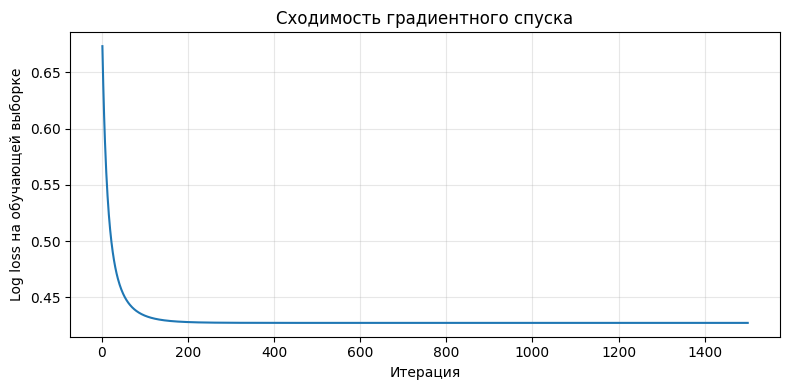

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(losses) + 1), losses)
plt.xlabel('Итерация')
plt.ylabel('Log loss на обучающей выборке')
plt.title('Сходимость градиентного спуска')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Оценка предсказаний

Качество проверяется **на тестовой выборке**, не использованной при настройке весов. Рассчитываются accuracy, precision, recall, F1 и матрица ошибок без библиотек машинного обучения. Дополнительно сравниваются истинные и предсказанные классы первых десяти объектов.

In [8]:
def classification_metrics(y_true, y_pred):
    actual = y_true.ravel()
    predicted = y_pred.ravel()
    tp = int(np.sum((actual == 1) & (predicted == 1)))
    tn = int(np.sum((actual == 0) & (predicted == 0)))
    fp = int(np.sum((actual == 0) & (predicted == 1)))
    fn = int(np.sum((actual == 1) & (predicted == 0)))
    accuracy = (tp + tn) / len(actual)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return accuracy, precision, recall, f1, np.array([[tn, fp], [fn, tp]])


y_pred_train = predict(w, X_train)
y_pred_test = predict(w, X_test)

for label, actual, predicted in [
    ('Обучающая', y_train, y_pred_train),
    ('Тестовая  ', y_test, y_pred_test),
]:
    accuracy, precision, recall, f1, matrix = classification_metrics(actual, predicted)
    print(f'{label}: accuracy={accuracy:.3f}, precision={precision:.3f}, '
          f'recall={recall:.3f}, F1={f1:.3f}')

_, _, _, _, confusion = classification_metrics(y_test, y_pred_test)
print('\nМатрица ошибок на тестовой выборке [строки: истинный класс 0/1; столбцы: прогноз 0/1]:')
print(confusion)
print('\nИстинные классы (первые 10):   ', y_test.ravel()[:10])
print('Предсказанные классы (первые 10):', y_pred_test.ravel()[:10])

Обучающая: accuracy=0.787, precision=0.776, recall=0.761, F1=0.768
Тестовая  : accuracy=0.821, precision=0.776, recall=0.839, F1=0.806

Матрица ошибок на тестовой выборке [строки: истинный класс 0/1; столбцы: прогноз 0/1]:
[[63 15]
 [10 52]]

Истинные классы (первые 10):    [1 0 1 0 0 0 0 1 0 0]
Предсказанные классы (первые 10): [1 0 0 0 0 0 0 1 1 0]


## 7. Визуализация предсказаний

Точки показывают объекты тестовой выборки с **истинными** метками. Прямая показывает границу решений обученной модели при пороге 0.5: $w_0+w_1x_1+w_2x_2=0$.

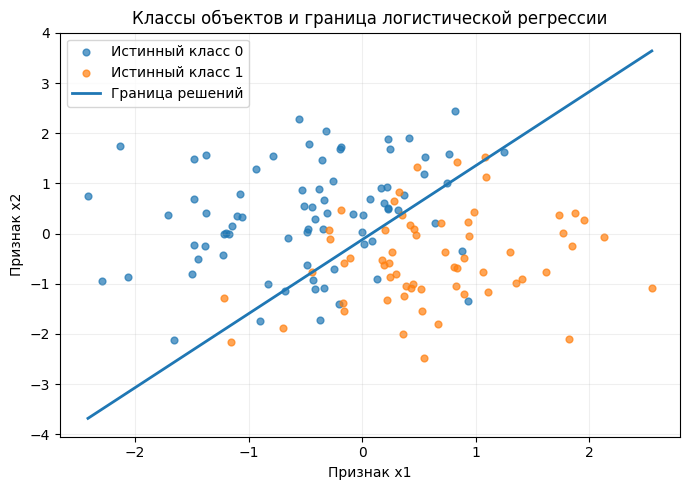

In [9]:
plt.figure(figsize=(7, 5))
for cls in (0, 1):
    mask = y_test.ravel() == cls
    plt.scatter(X_test[1, mask], X_test[2, mask],
                s=24, alpha=0.7, label=f'Истинный класс {cls}')

x1_grid = np.linspace(X_test[1].min(), X_test[1].max(), 200)
if abs(w[2, 0]) > 1e-12:
    x2_border = -(w[0, 0] + w[1, 0] * x1_grid) / w[2, 0]
    plt.plot(x1_grid, x2_border, linewidth=2, label='Граница решений')

plt.xlabel('Признак x1')
plt.ylabel('Признак x2')
plt.title('Классы объектов и граница логистической регрессии')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Выводы и ответы на дополнительные вопросы

**Результат эксперимента.** Градиент проверен численно, функция потерь уменьшается в ходе обучения. Найденные веса близки к параметрам, использованным при генерации данных, но не обязаны совпадать: метки создавались случайно по вероятностям. Метрики на тестовых данных показывают, насколько модель обобщает закономерность на новые объекты. Ошибки возможны даже у корректной модели, потому что классы в эксперименте не детерминированы.

**1. Как влияет шаг `eta` на сходимость?** Маленькая скорость обучения приводит к медленному уменьшению потерь. Слишком большая вызывает колебания или расходимость: при обновлении можно перескакивать через минимум. Разумную скорость обучения выбирают по устойчивому снижению log loss.

**2. Что будет при слишком малом или большом `n_iterations`?** При недостаточном числе шагов веса не успеют сойтись к хорошему решению, модель недообучится. При чрезмерном числе шагов вычисления могут оказаться избыточными; улучшения после сходимости становятся минимальными. На шумных данных длительное обучение также может ухудшать качество на новых наблюдениях, поэтому полезно отслеживать метрику на валидации и применять раннюю остановку.

**3. Почему логистическая регрессия предназначена для бинарной классификации?** В базовой форме она вычисляет одну вероятность $P(y=1\mid X)$ через сигмоиду, а вероятность второго класса равна $1-P(y=1\mid X)$. Поэтому исходная постановка — два класса. Для нескольких классов логистическая регрессия **может быть расширена**: через one-vs-rest или мультиномиальную (softmax) регрессию. Таким образом, ограничение относится к реализованному здесь бинарному варианту, а не ко всему семейству моделей.